# A3: Classical model results

Read-only review of the tuning and final runs of logistic regression and random forest on the handcrafted features. Nothing is fitted, predicted or tuned here: all numbers come from `results/` and `runs/`, and test images are loaded only for display.

## 1. Setup

Loads the results CSVs and stops if any of the 30 final runs (2 models × 3 resolutions × 5 seeds) or 6 tuning sweeps is missing. Final run folders are found through the `run_name` column of `results/classical_runs.csv`.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display


def find_repo_root(start):
    for folder in (start, *start.parents):
        if (folder / "src" / "data.py").is_file():
            return folder
    raise FileNotFoundError(f"No folder containing src/data.py found at or above {start}.")


REPO_ROOT = find_repo_root(Path.cwd().resolve())
sys.path.insert(0, str(REPO_ROOT / "src"))

from classical import MODELS
from data import CLASS_SHORT_NAMES, RESOLUTIONS, load_split
from evaluate import CLASS_KEYS, DPI, draw_confusion_matrix
from run_classical import load_tuned, results_csvs
from tune_classical import RESULTS_DIR, RUNS_DIR, format_settings, tuning_csv, tuning_stem

MODEL_NAMES = {"LogisticRegression": "Logistic regression", "RandomForest": "Random forest"}
MODEL_COLORS = {"LogisticRegression": "tab:blue", "RandomForest": "tab:orange"}
RUN_KEYS = [(model, res) for model in MODELS for res in RESOLUTIONS]
EXPECTED_RUNS = 30
EXPECTED_SWEEPS = 6
SHOW_SEED = 0
CONFUSION_RESOLUTION = 128
TOP_CORRECT = 3
FIGURES_DIR = REPO_ROOT / "figures"
FIGURES_DIR.mkdir(exist_ok=True)

pd.set_option("display.precision", 4)

In [2]:
runs_path, summary_path = results_csvs(test_run=False)
runs = pd.read_csv(runs_path)
summary = pd.read_csv(summary_path).set_index(["model", "resolution"]).loc[RUN_KEYS]
extraction = pd.read_csv(RESULTS_DIR / "extraction_time.csv")
tuning_paths = {key: tuning_csv(tuning_stem(*key, test=False)) for key in RUN_KEYS}

found = [path for path in tuning_paths.values() if path.is_file()]
print(f"Final runs: {len(runs)} (expected {EXPECTED_RUNS})")
print(f"Tuning CSVs: {len(found)} (expected {EXPECTED_SWEEPS})")
if len(runs) != EXPECTED_RUNS or len(found) != EXPECTED_SWEEPS:
    raise ValueError("Final runs or tuning CSVs are missing; complete them before this notebook.")
tuning = {key: pd.read_csv(path) for key, path in tuning_paths.items()}

missing = [name for name in runs["run_name"] if not (RUNS_DIR / name).is_dir()]
if missing:
    raise FileNotFoundError(f"Run folders listed in {runs_path.name} are missing: {missing}")
seed_runs = runs[runs["seed"] == SHOW_SEED].set_index(["model", "resolution"])["run_name"]
display_index = summary.rename(index=MODEL_NAMES, level="model").index.rename(
    ["Model", "Resolution (px)"]
)


def seed_run_dir(model, res):
    return RUNS_DIR / seed_runs[model, res]


def load_predictions(model, res):
    return pd.read_csv(seed_run_dir(model, res) / "predictions.csv")


def class_indices(names):
    return np.array([CLASS_SHORT_NAMES.index(name) for name in names])

Final runs: 30 (expected 30)
Tuning CSVs: 6 (expected 6)


## 2. Tuning

Validation macro F1 of all 20 tries per sweep, sorted from best to worst. The red star is the try used for the final runs, picked by `load_tuned` from `src/run_classical.py` (highest val macro F1, val accuracy as tie-breaker).

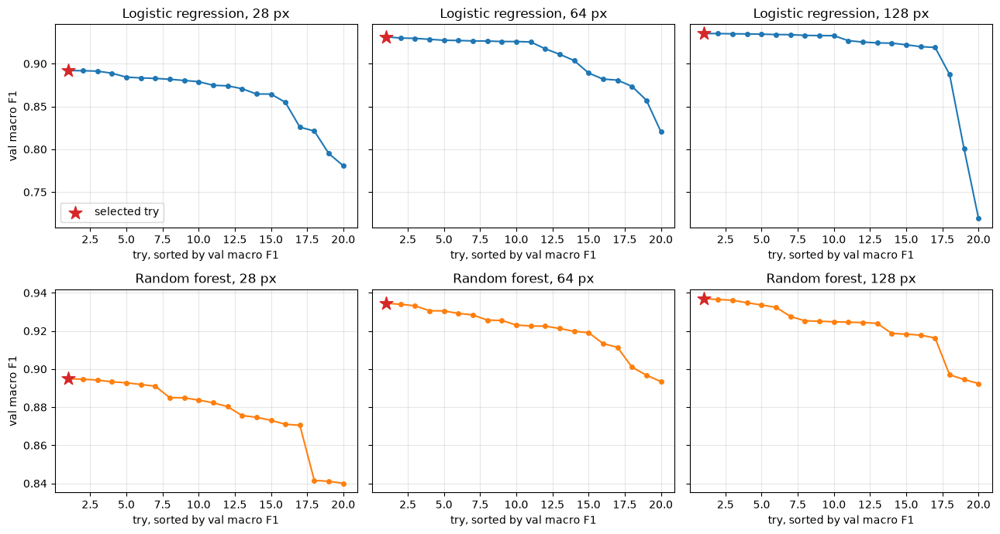

In [3]:
tuned = {key: load_tuned(*key) for key in RUN_KEYS}

fig, axes = plt.subplots(len(MODELS), len(RESOLUTIONS), figsize=(13, 7), sharey="row")
for (model, res), ax in zip(RUN_KEYS, axes.ravel()):
    tries = tuning[model, res].sort_values(["val_macro_f1", "val_accuracy"], ascending=False)
    ranks = np.arange(1, len(tries) + 1)
    best_rank = ranks[(tries["run_id"] == tuned[model, res].run_id).to_numpy()][0]
    ax.plot(ranks, tries["val_macro_f1"], marker="o", markersize=4, color=MODEL_COLORS[model])
    ax.scatter(
        best_rank,
        float(tuned[model, res].val_macro_f1),
        s=160,
        marker="*",
        color="tab:red",
        zorder=3,
        label="selected try",
    )
    ax.set_title(f"{MODEL_NAMES[model]}, {res} px")
    ax.set_xlabel("try, sorted by val macro F1")
    ax.grid(alpha=0.3)
for ax in axes[:, 0]:
    ax.set_ylabel("val macro F1")
axes[0, 0].legend(loc="lower left")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "A3_tuning.png", dpi=DPI)
plt.show()

Best settings per model and resolution, with the W&B run id of the selected tuning try.

In [4]:
best_settings = pd.DataFrame(
    {
        "settings": [format_settings(tuned[key].settings) for key in RUN_KEYS],
        "val macro F1": [float(tuned[key].val_macro_f1) for key in RUN_KEYS],
        "tuning run": [tuned[key].run_id for key in RUN_KEYS],
    },
    index=display_index,
)
best_settings

settings  \
Model               Resolution (px)                                                      
Logistic regression 28                                                        C=0.2876   
                    64                                                        C=0.1911   
                    128                                                       C=0.5632   
Random forest       28               n_estimators=493, max_depth=40, max_features=0...   
                    64               n_estimators=138, max_depth=None, max_features...   
                    128              n_estimators=305, max_depth=20, max_features=0...   

                                     val macro F1 tuning run  
Model               Resolution (px)                           
Logistic regression 28                     0.8920   s2ibra9n  
                    64                     0.9314   d37xdkb1  
                    128                    0.9353   x1rlp5gt  
Random forest       28                     0.8949   bi28juol  
                    64                     0.9345   82a1dkgo  
                    128                    0.9370   d4lumzq9

Check that every final run used exactly these settings.

In [5]:
for (model, res), best in tuned.items():
    used = runs.loc[(runs["model"] == model) & (runs["resolution"] == res), "settings"]
    if any(json.loads(settings) != best.settings for settings in used):
        raise ValueError(f"{model} at {res} px: final runs differ from the best tuned settings.")
print("All final runs used the best tuned settings.")

All final runs used the best tuned settings.


## 3. Final test results

Test results in the format of Table I in the paper. Accuracy and macro F1 are mean ± sample standard deviation over the 5 seeds, in percent. Fit time (train split), prediction time per test image and model size (`model.joblib`, 1 MB = 10^6 bytes) are means over the seeds.

In [6]:
def mean_std_percent(column):
    means = summary[f"{column}_mean"] * 100
    stds = summary[f"{column}_std"] * 100
    return [f"{mean:.2f} ± {std:.2f}" for mean, std in zip(means, stds)]


results_table = pd.DataFrame(
    {
        "Accuracy (%)": mean_std_percent("test_accuracy"),
        "Macro F1 (%)": mean_std_percent("test_macro_f1"),
        "Fit (s)": [f"{v:.2f}" for v in summary["fit_seconds_mean"]],
        "Prediction (µs/image)": [f"{v:.2f}" for v in summary["predict_us_per_image_mean"]],
        "Size (MB)": [f"{v / 1e6:.2f}" for v in summary["model_bytes_mean"]],
    },
    index=display_index,
)
results_table

Accuracy (%)  Macro F1 (%) Fit (s)  \
Model               Resolution (px)                                       
Logistic regression 28               89.17 ± 0.00  87.80 ± 0.00    0.74   
                    64               93.32 ± 0.00  92.98 ± 0.00    0.70   
                    128              93.44 ± 0.00  93.11 ± 0.00    0.65   
Random forest       28               89.85 ± 0.10  88.47 ± 0.11   94.93   
                    64               92.95 ± 0.13  92.46 ± 0.15   30.59   
                    128              93.79 ± 0.10  93.42 ± 0.12   19.36   

                                    Prediction (µs/image) Size (MB)  
Model               Resolution (px)                                  
Logistic regression 28                               0.91      0.02  
                    64                               0.88      0.02  
                    128                              0.88      0.02  
Random forest       28                              40.06     72.56  
                    64                              11.64     20.87  
                    128                             23.90     48.72

## 4. Per-class recall

Test recall per class, mean over the 5 seeds, with both models side by side for each class.

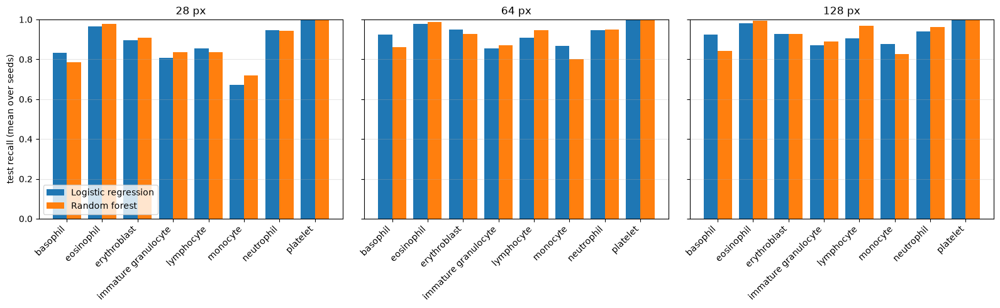

In [7]:
recall_columns = [f"test_recall_{key}_mean" for key in CLASS_KEYS]
positions = np.arange(len(CLASS_SHORT_NAMES))
width = 0.8 / len(MODELS)

fig, axes = plt.subplots(1, len(RESOLUTIONS), figsize=(16, 5), sharey=True)
for ax, res in zip(axes, RESOLUTIONS):
    for i, model in enumerate(MODELS):
        offset = (i - (len(MODELS) - 1) / 2) * width
        ax.bar(
            positions + offset,
            summary.loc[(model, res), recall_columns],
            width,
            label=MODEL_NAMES[model],
            color=MODEL_COLORS[model],
        )
    ax.set_xticks(positions, CLASS_SHORT_NAMES, rotation=45, ha="right")
    ax.set_title(f"{res} px")
    ax.set_ylim(0, 1)
    ax.grid(axis="y", alpha=0.3)
axes[0].set_ylabel("test recall (mean over seeds)")
axes[0].legend(loc="lower left")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "A3_per_class_recall.png", dpi=DPI)
plt.show()

## 5. Confusion matrices

Seed 0 of both models at 128 px, recomputed from `predictions.csv` with `draw_confusion_matrix` from `src/evaluate.py`, the same code that draws the run plots: counts in the cells, colour by the fraction of the true class.

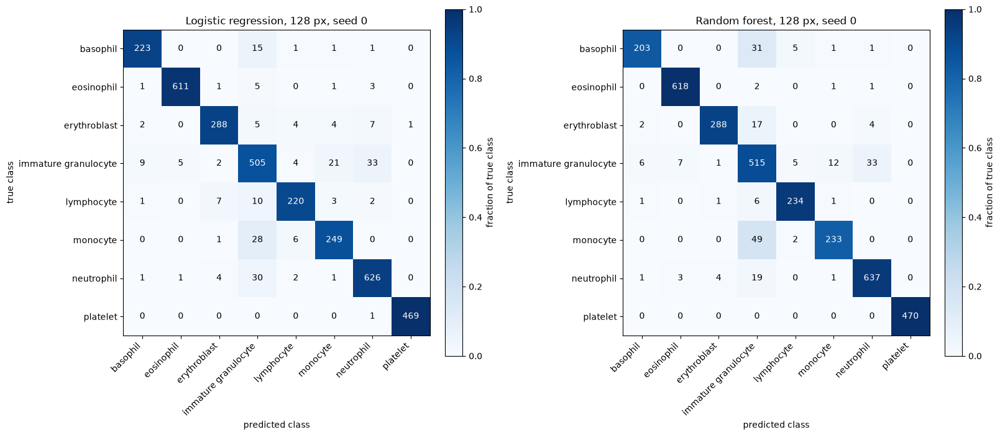

In [8]:
fig, axes = plt.subplots(1, len(MODELS), figsize=(16, 7), layout="constrained")
for ax, model in zip(axes, MODELS):
    predictions = load_predictions(model, CONFUSION_RESOLUTION)
    draw_confusion_matrix(
        ax, class_indices(predictions["true_class"]), class_indices(predictions["predicted_class"])
    )
    ax.set_title(f"{MODEL_NAMES[model]}, {CONFUSION_RESOLUTION} px, seed {SHOW_SEED}")
fig.savefig(FIGURES_DIR / "A3_confusion_matrices.png", dpi=DPI)
plt.show()

The confusion matrices saved by the six seed-0 runs (`plots/confusion_matrix.png`).

Logistic regression, 28 px, seed 0: BloodCellClassification_LogisticRegression_bloodmnist28_20261126_125001


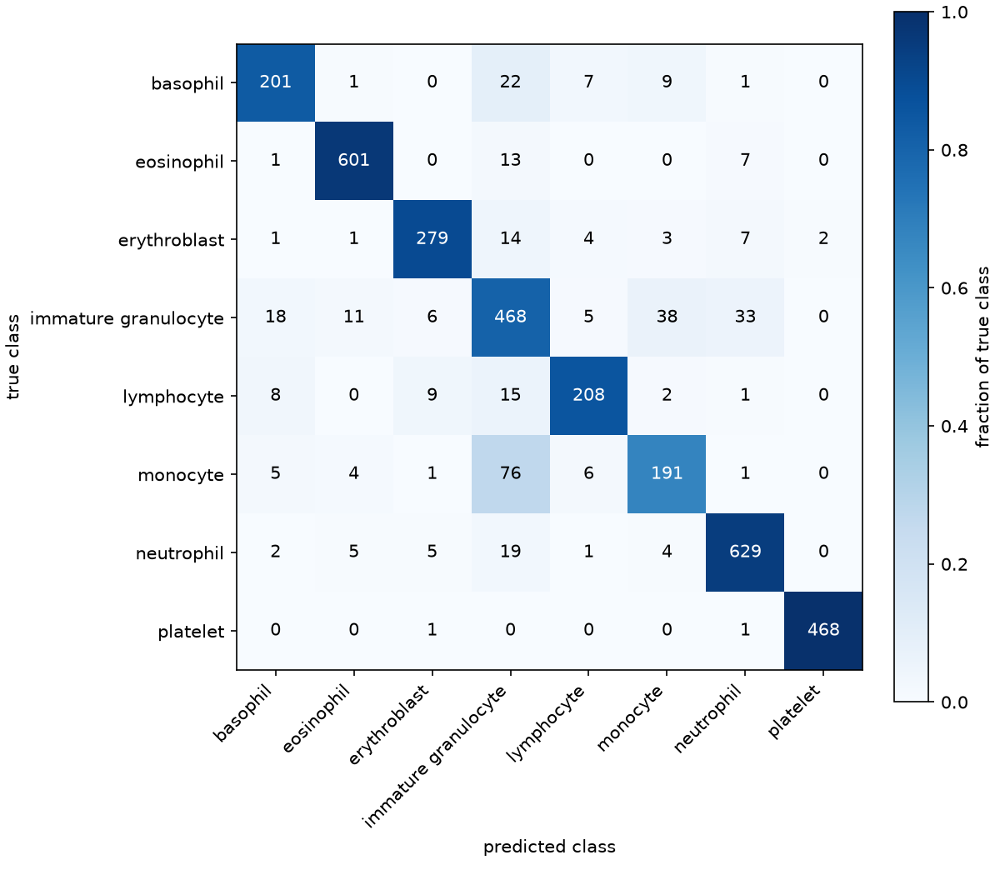

Logistic regression, 64 px, seed 0: BloodCellClassification_LogisticRegression_bloodmnist64_20261126_125912


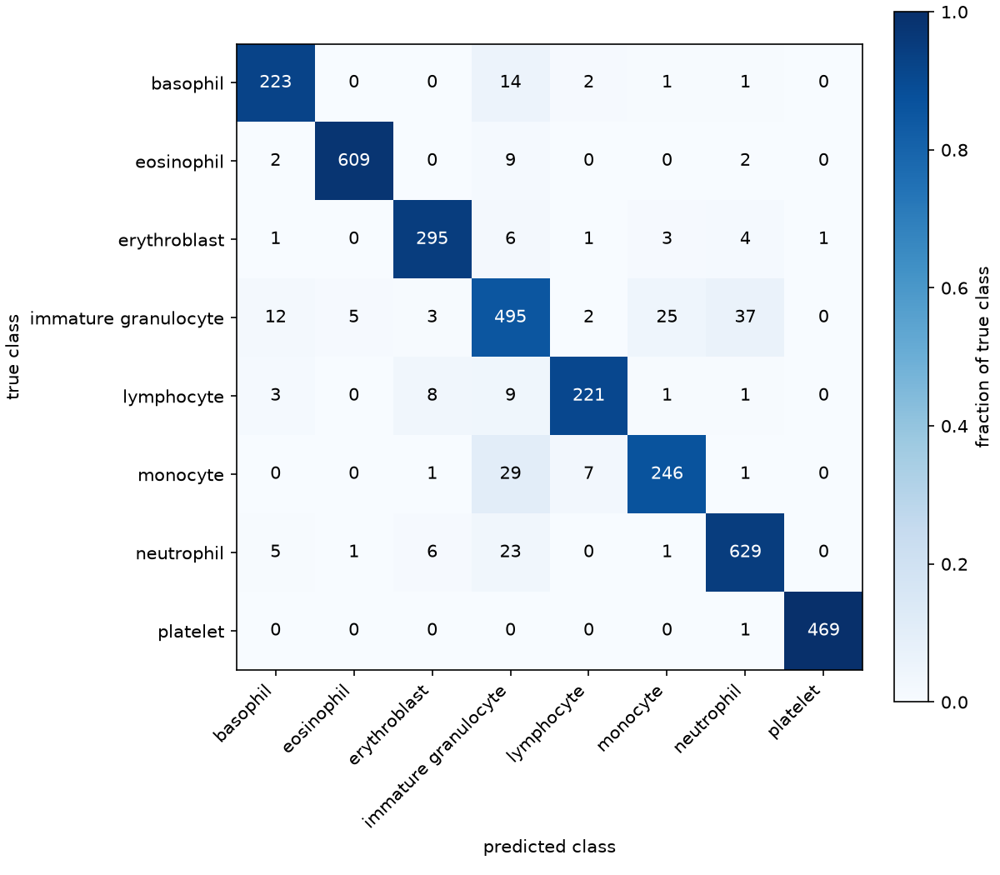

Logistic regression, 128 px, seed 0: BloodCellClassification_LogisticRegression_bloodmnist128_20261126_130300


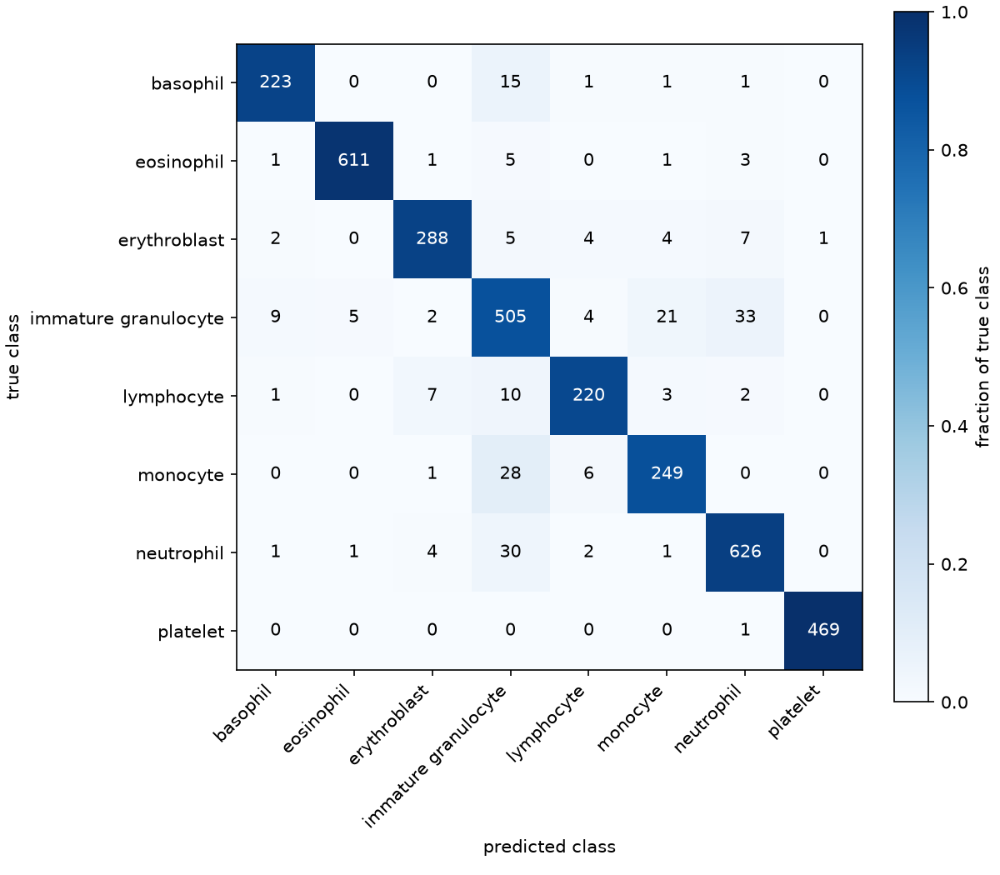

Random forest, 28 px, seed 0: BloodCellClassification_RandomForest_bloodmnist28_20261126_125042


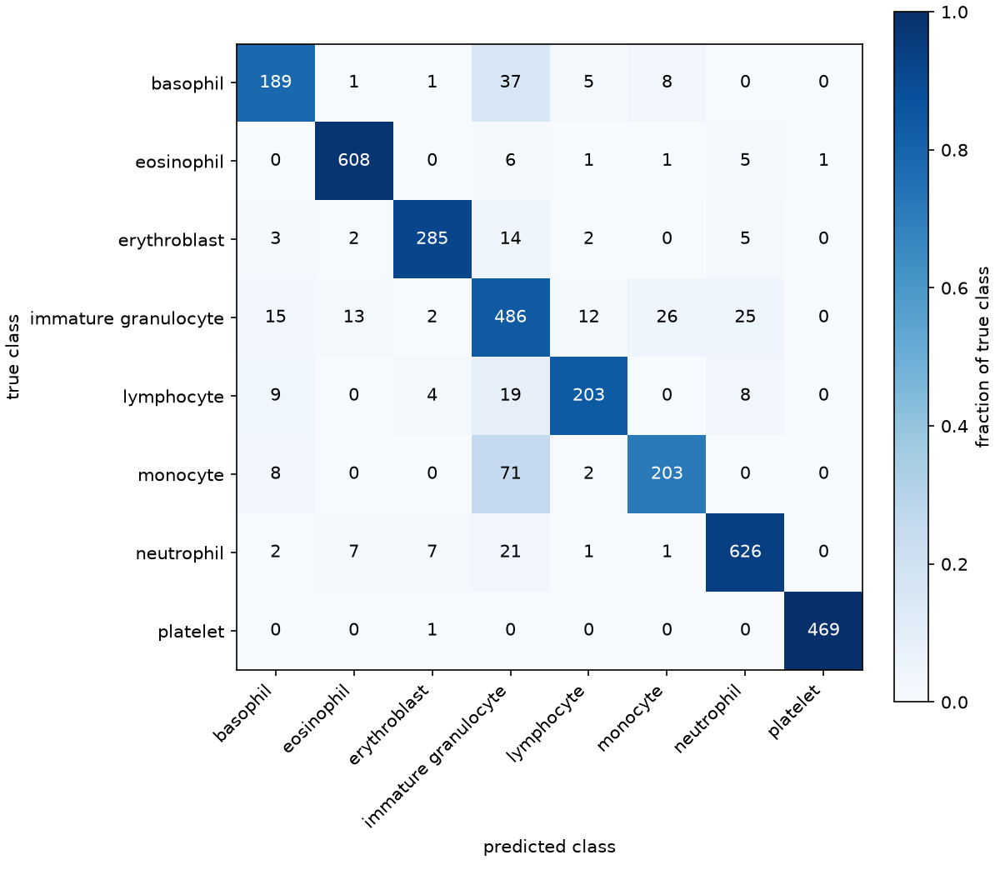

Random forest, 64 px, seed 0: BloodCellClassification_RandomForest_bloodmnist64_20261126_125951


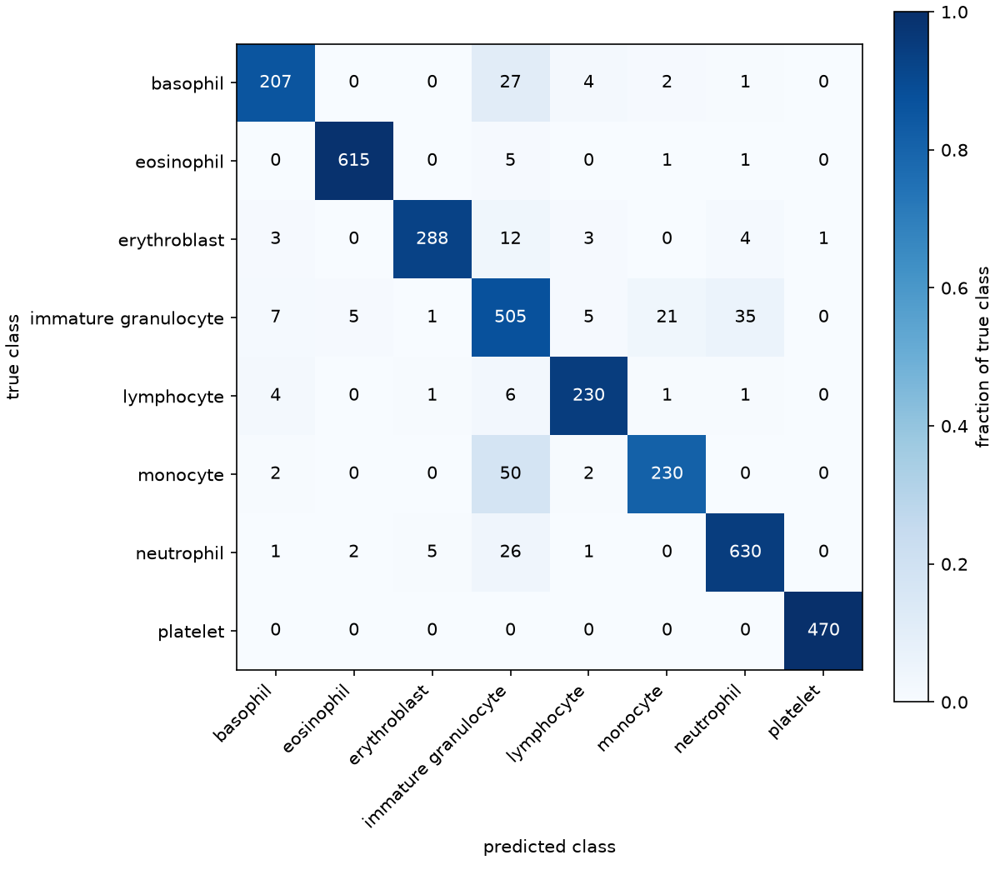

Random forest, 128 px, seed 0: BloodCellClassification_RandomForest_bloodmnist128_20261126_130344


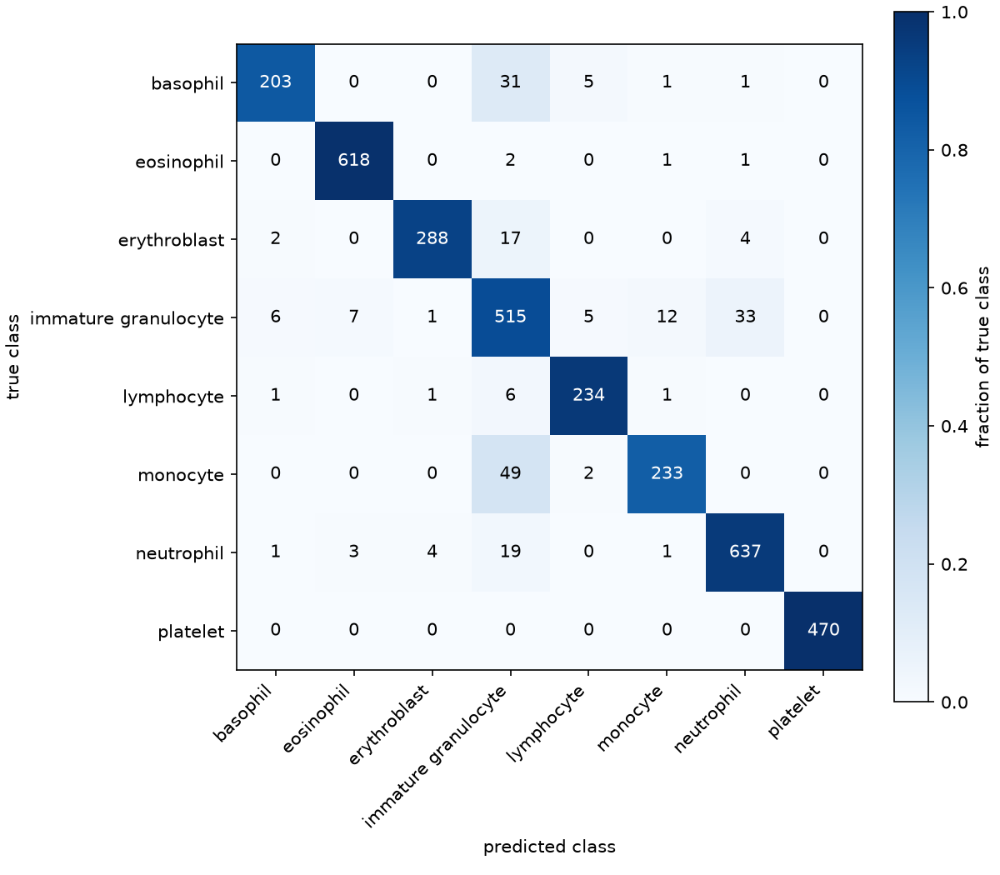

In [9]:
def show_run_plots(filename, width):
    for model, res in RUN_KEYS:
        print(f"{MODEL_NAMES[model]}, {res} px, seed {SHOW_SEED}: {seed_runs[model, res]}")
        display(Image(filename=str(seed_run_dir(model, res) / "plots" / filename), width=width))


show_run_plots("confusion_matrix.png", width=600)

## 6. Misclassified examples

Up to 36 wrongly predicted test images per seed-0 run, in dataset index order (`plots/misclassified.png`).

Logistic regression, 28 px, seed 0: BloodCellClassification_LogisticRegression_bloodmnist28_20261126_125001


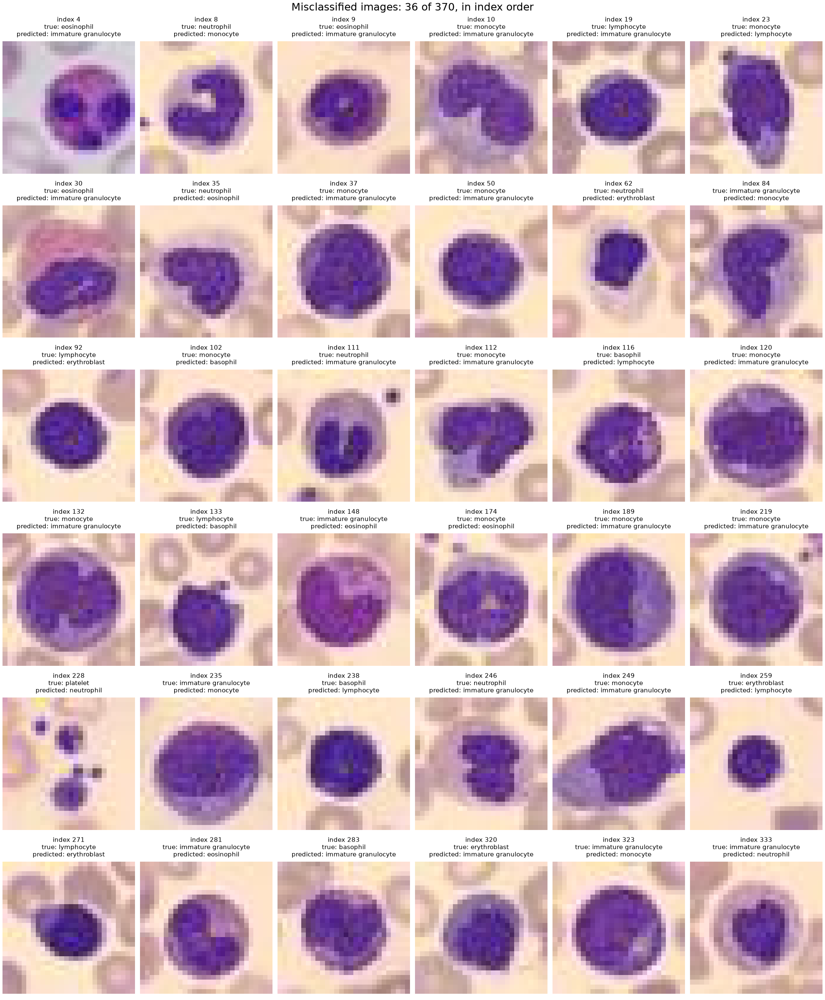

Logistic regression, 64 px, seed 0: BloodCellClassification_LogisticRegression_bloodmnist64_20261126_125912


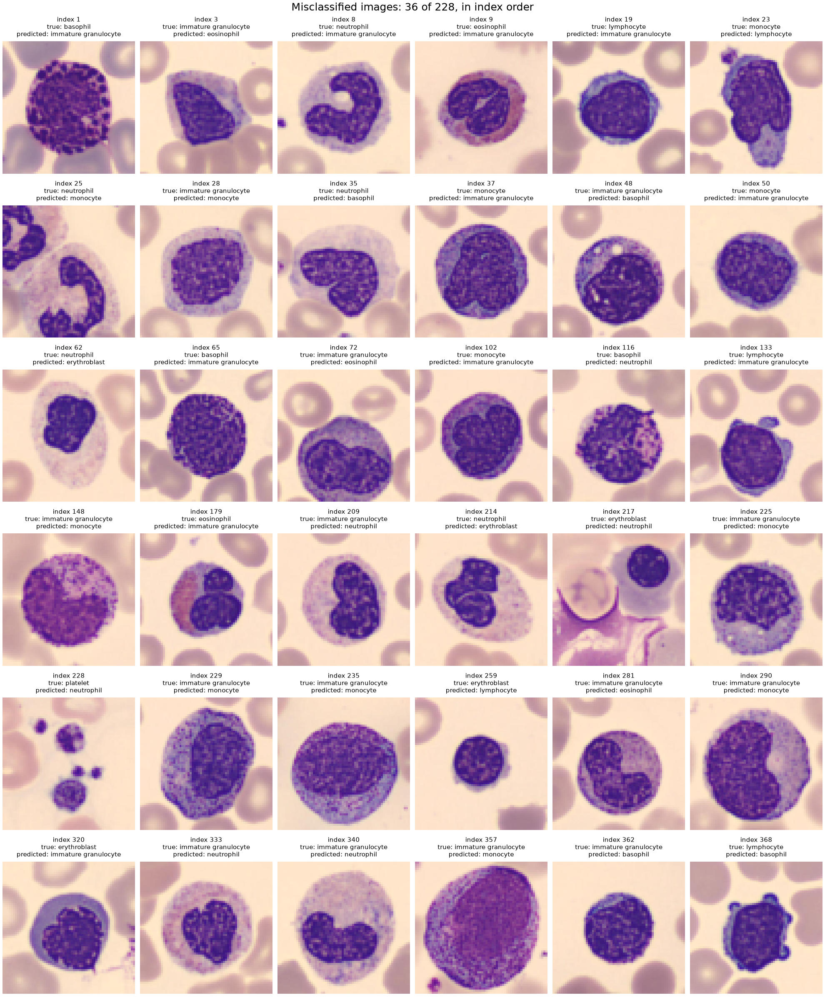

Logistic regression, 128 px, seed 0: BloodCellClassification_LogisticRegression_bloodmnist128_20261126_130300


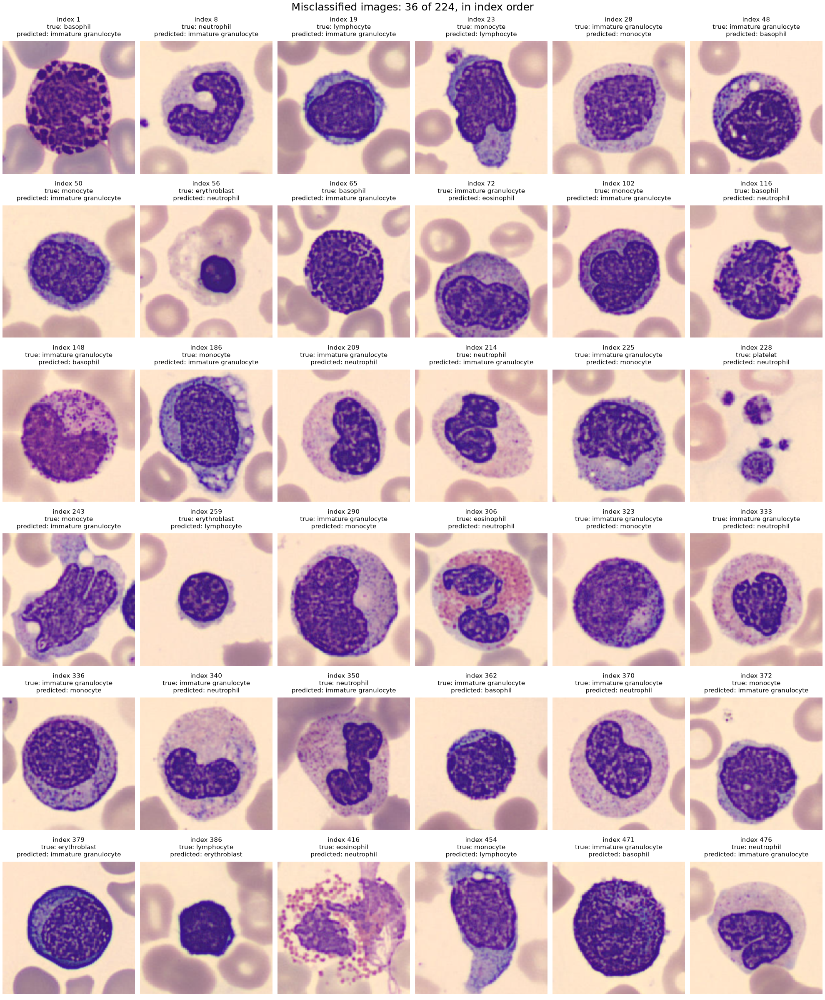

Random forest, 28 px, seed 0: BloodCellClassification_RandomForest_bloodmnist28_20261126_125042


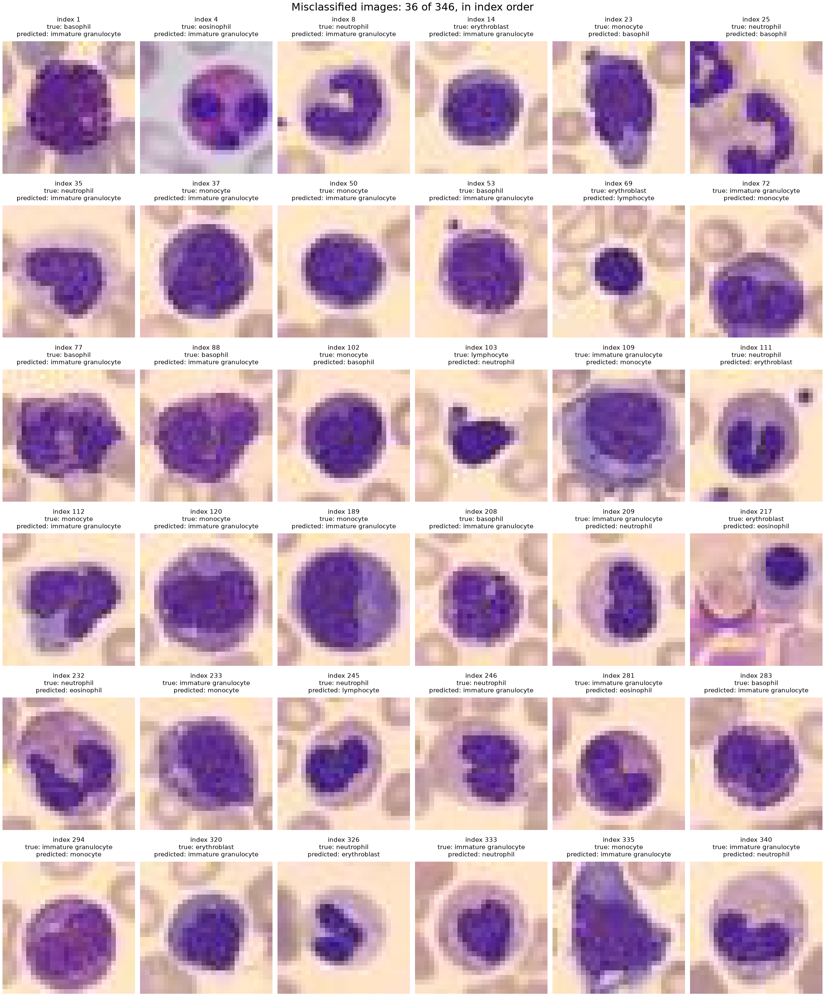

Random forest, 64 px, seed 0: BloodCellClassification_RandomForest_bloodmnist64_20261126_125951


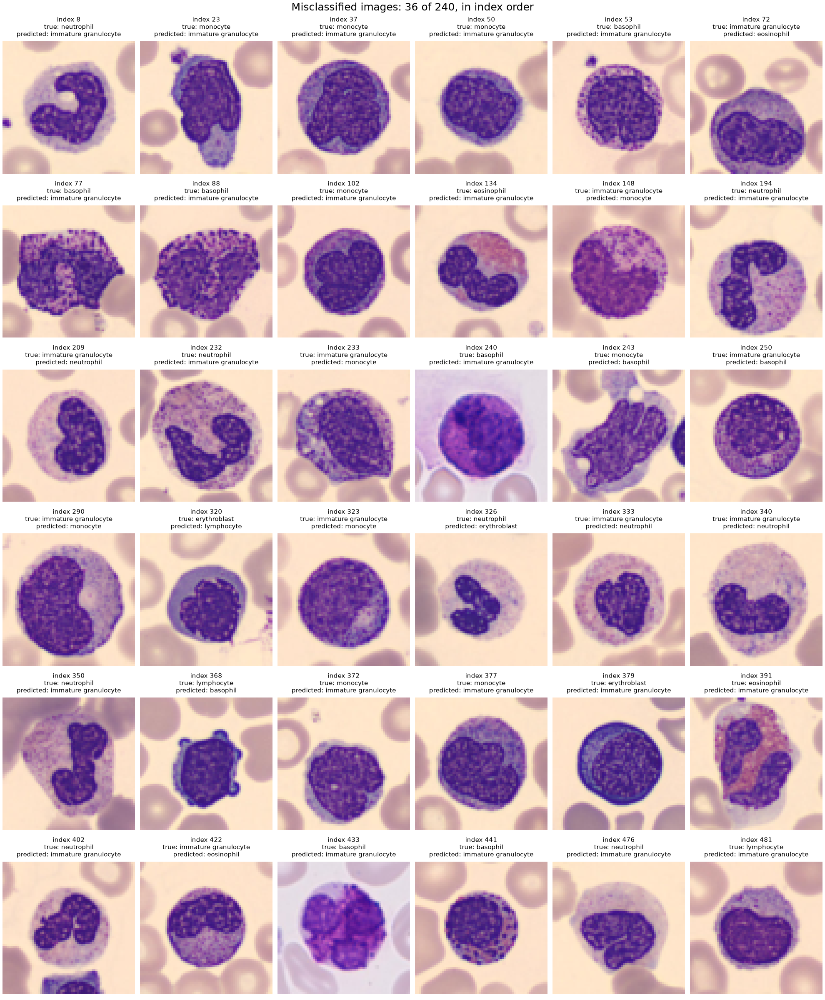

Random forest, 128 px, seed 0: BloodCellClassification_RandomForest_bloodmnist128_20261126_130344


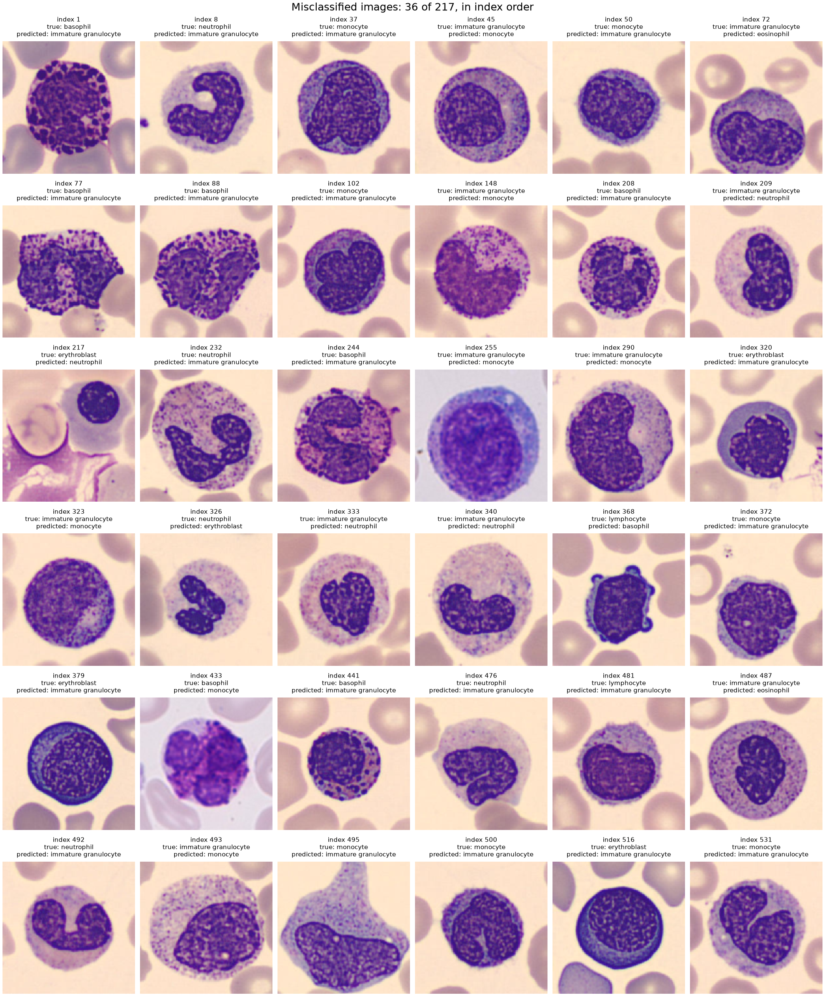

In [10]:
show_run_plots("misclassified.png", width=900)

## 7. Correctly classified examples

For each seed-0 run and class, the 3 correctly predicted test images with the highest predicted probability for their class; ties go to the lower dataset index. Images are loaded with `load_split` and matched to `predictions.csv` through the dataset index.

In [11]:
test_images = {}
for res in RESOLUTIONS:
    images, _, indices = load_split(res, "test")
    test_images[res] = (images, pd.Series(np.arange(len(indices)), index=indices))


def test_positions(res, indices):
    """Positions in the loaded test split of the given dataset indices."""
    lookup = test_images[res][1]
    missing = np.setdiff1d(indices, lookup.index)
    if missing.size:
        raise KeyError(f"Dataset indices not in the {res} px test split: {missing[:10].tolist()}")
    return lookup[indices].to_numpy()

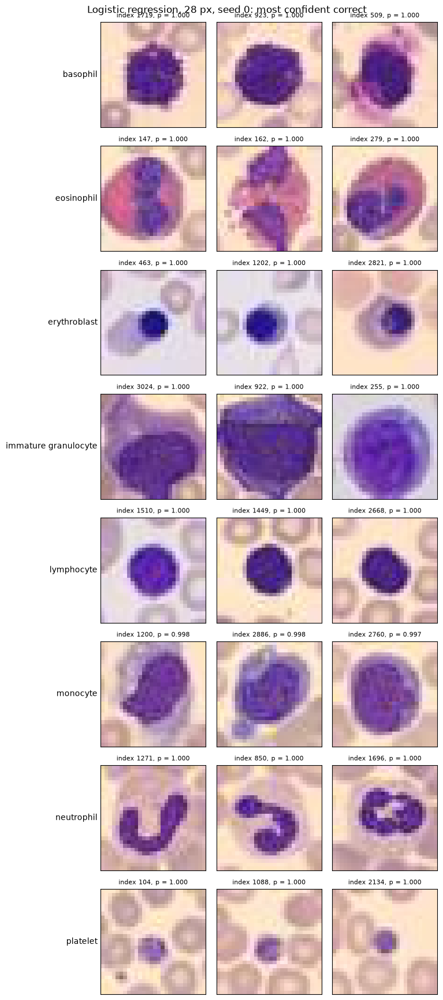

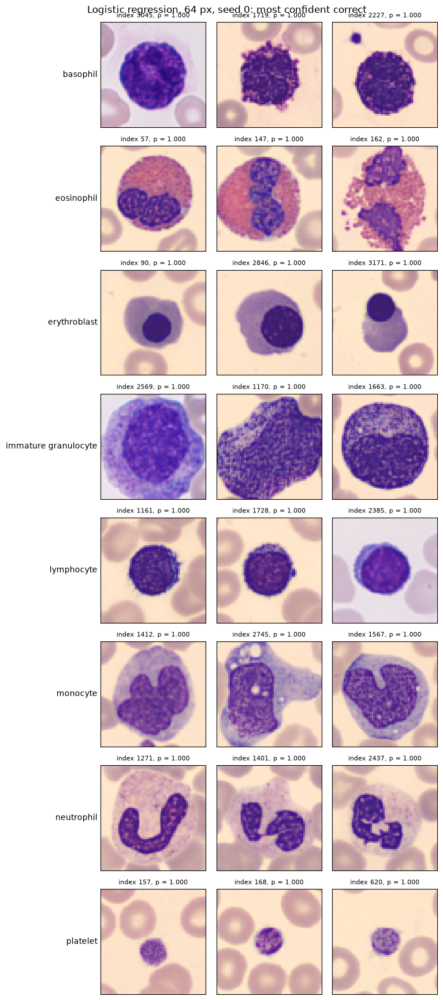

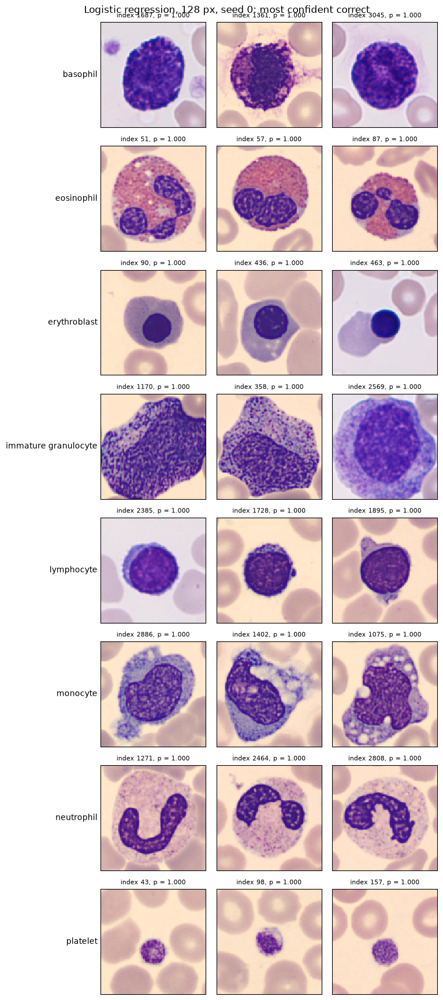

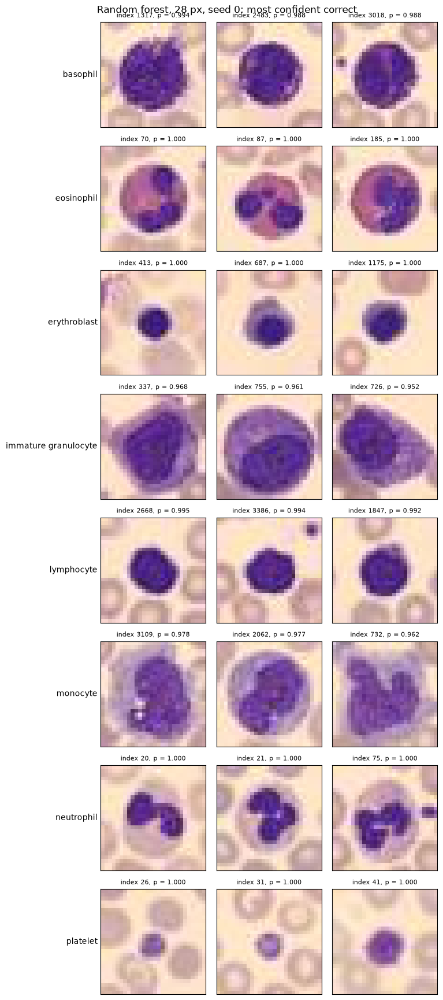

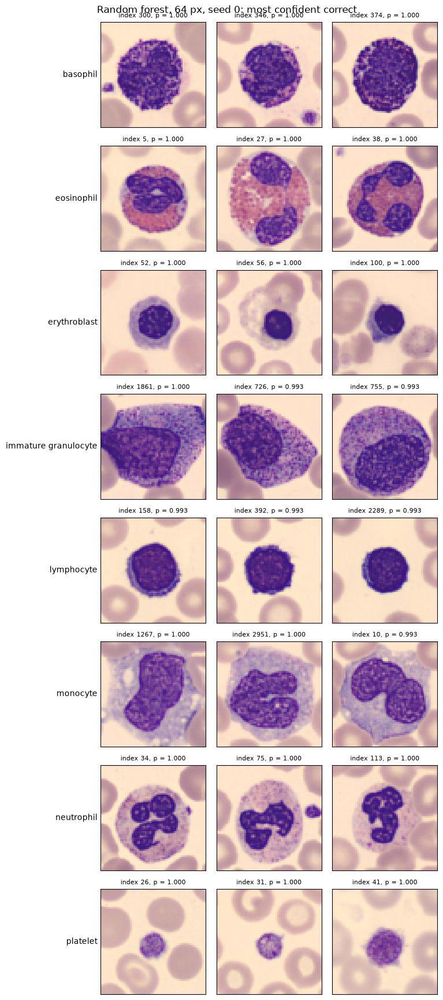

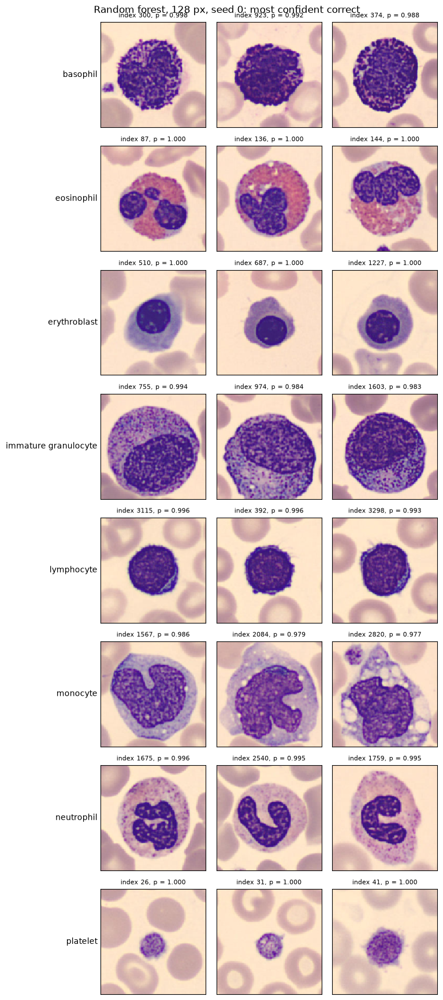

In [12]:
for model, res in RUN_KEYS:
    predictions = load_predictions(model, res)
    predictions["position"] = test_positions(res, predictions["index"].to_numpy())
    images = test_images[res][0]

    fig, axes = plt.subplots(
        len(CLASS_SHORT_NAMES),
        TOP_CORRECT,
        figsize=(2 * TOP_CORRECT + 2, 2.2 * len(CLASS_SHORT_NAMES)),
    )
    for row, (name, key) in enumerate(zip(CLASS_SHORT_NAMES, CLASS_KEYS)):
        correct = predictions[
            (predictions["true_class"] == name) & (predictions["predicted_class"] == name)
        ]
        top = correct.nlargest(TOP_CORRECT, f"prob_{key}")
        for col, ax in enumerate(axes[row]):
            ax.set_xticks([])
            ax.set_yticks([])
            if col < len(top):
                example = top.iloc[col]
                ax.imshow(images[example["position"]], interpolation="nearest")
                ax.set_title(
                    f"index {example['index']}, p = {example[f'prob_{key}']:.3f}", fontsize=8
                )
        axes[row, 0].set_ylabel(name, rotation=0, ha="right", va="center")
    fig.suptitle(f"{MODEL_NAMES[model]}, {res} px, seed {SHOW_SEED}: most confident correct")
    fig.tight_layout()
    plt.show()

## 8. Cost

Mean fit time, prediction time per test image and model size per model and resolution, next to the feature extraction time per test image from `results/extraction_time.csv` (one process). The classifiers work on the extracted features, so classifying a new image costs extraction plus prediction.

In [13]:
extraction_ms = extraction[extraction["split"] == "test"].set_index("resolution")["ms_per_image"]
cost = pd.DataFrame(
    {
        "Fit (s)": summary["fit_seconds_mean"].to_numpy(),
        "Prediction (µs/image)": summary["predict_us_per_image_mean"].to_numpy(),
        "Size (MB)": (summary["model_bytes_mean"] / 1e6).to_numpy(),
        "Feature extraction (ms/image)": extraction_ms.reindex(
            summary.index.get_level_values("resolution")
        ).to_numpy(),
    },
    index=display_index,
)
cost["Extraction + prediction (ms/image)"] = (
    cost["Feature extraction (ms/image)"] + cost["Prediction (µs/image)"] / 1000
)
cost.round(3)

Fit (s)  Prediction (µs/image)  \
Model               Resolution (px)                                   
Logistic regression 28                 0.740                  0.908   
                    64                 0.699                  0.876   
                    128                0.653                  0.884   
Random forest       28                94.928                 40.064   
                    64                30.587                 11.645   
                    128               19.357                 23.896   

                                     Size (MB)  Feature extraction (ms/image)  \
Model               Resolution (px)                                             
Logistic regression 28                   0.023                         24.066   
                    64                   0.023                         26.518   
                    128                  0.023                         62.623   
Random forest       28                  72.555                         24.066   
                    64                  20.875                         26.518   
                    128                 48.719                         62.623   

                                     Extraction + prediction (ms/image)  
Model               Resolution (px)                                      
Logistic regression 28                                           24.067  
                    64                                           26.519  
                    128                                          62.624  
Random forest       28                                           24.106  
                    64                                           26.530  
                    128                                          62.647